# GEC-RAG Project
## Notebook 08 — Analysis & Paper Figures

This notebook produces all final figures, tables, and statistical analysis for the paper.

**Covers:**
- Final combined results table (F0.5 + G-Eval)
- G-Eval dimension comparison figures (publication quality)
- Per error-type analysis
- Actionability deep dive (key finding)
- RAG coverage analysis
- Score distribution analysis
- Statistical significance testing
- Qualitative examples for paper

---
### Cell 1 — Imports & Setup

In [1]:
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

BASE_DIR    = 'C:/gecrag'
RESULTS_DIR = os.path.join(BASE_DIR, 'results')
FIGURES_DIR = os.path.join(BASE_DIR, 'figures')
os.makedirs(FIGURES_DIR, exist_ok=True)

# Global figure settings for publication quality
plt.rcParams.update({
    'font.size'        : 14,
    'axes.titlesize'   : 16,
    'axes.labelsize'   : 14,
    'xtick.labelsize'  : 13,
    'ytick.labelsize'  : 13,
    'legend.fontsize'  : 12,
    'figure.dpi'       : 150,
    'savefig.dpi'      : 300,
    'savefig.bbox'     : 'tight',
    'font.family'      : 'sans-serif',
})

print('\u2705 Setup complete')
print(f'   Figures will be saved to: {FIGURES_DIR}')

✅ Setup complete
   Figures will be saved to: C:/gecrag\figures


---
### Cell 2 — Load All Results

In [2]:
# Load F0.5 scores
with open(os.path.join(RESULTS_DIR, 'baseline_scores.json'), 'r') as f:
    f05_scores = json.load(f)

# Load G-Eval summary
with open(os.path.join(RESULTS_DIR, 'geval_results.json'), 'r') as f:
    geval_results = json.load(f)
geval_summaries = {s['system']: s for s in geval_results['summaries']}

# Load raw G-Eval scores per system
geval_raw = {}
for name, label in [
    ('gpt4o',       'GPT-4o (no RAG)'),
    ('llama',       'Llama 3.1 (no RAG)'),
    ('gecrag',      'GEC-RAG'),
    ('human_norag', 'Human + no RAG'),
    ('human_rag',   'Human + RAG'),
]:
    path = os.path.join(RESULTS_DIR, f'geval_{name}.csv')
    if os.path.exists(path):
        geval_raw[label] = pd.read_csv(path)
        print(f'\u2705 {label:<25} : {len(geval_raw[label])} rows')
    else:
        print(f'\u26a0\ufe0f  {label:<25} : not found')

# Load per-type scores
per_type = {}
for name, label in [
    ('t5_per_type_scores',       'T5-GEC'),
    ('gpt4o_per_type_scores',    'GPT-4o (no RAG)'),
    ('llama_per_type_scores',    'Llama 3.1 (no RAG)'),
    ('gecrag_per_type_scores',   'GEC-RAG'),
]:
    path = os.path.join(RESULTS_DIR, f'{name}.csv')
    if os.path.exists(path):
        per_type[label] = pd.read_csv(path)

print(f'\n\u2705 All results loaded')

✅ GPT-4o (no RAG)           : 3723 rows
✅ Llama 3.1 (no RAG)        : 3825 rows
✅ GEC-RAG                   : 3740 rows
✅ Human + no RAG            : 2880 rows
✅ Human + RAG               : 2880 rows

✅ All results loaded


---
### Cell 3 — Complete Results Table (Paper Table 1)

In [3]:
# System display order for paper
SYSTEMS = [
    ('T5-GEC',              'T5-GEC',                    True,  False),
    ('GPT-4o (no RAG)',     'GPT-4o-mini (no RAG)',      True,  True),
    ('Llama 3.1 (no RAG)', 'Llama-3.1-8B (no RAG)',     True,  True),
    ('GEC-RAG',             'GEC-RAG (GPT-4o-mini + KB)', True, True),
    ('Human + no RAG',      None,                         False, True),
    ('Human + RAG',         None,                         False, True),
]

sep = '='*95
print(sep)
print('TABLE 1: COMPLETE RESULTS')
print('Correction Quality (F0.5) and Explanation Quality (G-Eval, 1-5 scale)')
print(sep)
print(f'\n  {"System":<28} {"F0.5":>6} | {"Clarity":>8} {"Accuracy":>9} {"Relevance":>10} {"Action":>8} {"Avg":>6}')
print(f'  {"-"*91}')

for display_name, f05_key, has_f05, has_geval in SYSTEMS:
    # F0.5
    if has_f05 and f05_key and f05_key in f05_scores:
        f05 = f'{f05_scores[f05_key]["f05"]}%'
    elif has_f05:
        f05 = 'N/A'
    else:
        f05 = '—'

    # G-Eval
    if has_geval and display_name in geval_summaries:
        s = geval_summaries[display_name]
        geval_str = (
            f'{s["clarity_mean"]:>7.3f}  '
            f'{s["accuracy_mean"]:>8.3f}  '
            f'{s["relevance_mean"]:>9.3f}  '
            f'{s["actionability_mean"]:>7.3f} '
            f'{s["average_mean"]:>6.3f}'
        )
    else:
        geval_str = f'  {"N/A":>7}  {"N/A":>8}  {"N/A":>9}  {"N/A":>7} {"N/A":>6}'

    marker = ' \u25c4' if display_name == 'GEC-RAG' else (' \u25b2' if 'Human' in display_name else '')
    print(f'  {display_name:<28} {f05:>6} | {geval_str}{marker}')

print(f'\n  \u25c4 = Our proposed system')
print(f'  \u25b2 = Human upper bound (reference corrections used directly)')
print(f'  F0.5: standard GEC metric (higher = better correction quality)')
print(f'  G-Eval: explanation quality rated by GPT-4o judge (Liu et al. 2023)')

TABLE 1: COMPLETE RESULTS
Correction Quality (F0.5) and Explanation Quality (G-Eval, 1-5 scale)

  System                         F0.5 |  Clarity  Accuracy  Relevance   Action    Avg
  -------------------------------------------------------------------------------------------
  T5-GEC                       40.93% |       N/A       N/A        N/A      N/A    N/A
  GPT-4o (no RAG)              39.82% |   4.258     4.858      4.727    3.846  4.422
  Llama 3.1 (no RAG)           33.08% |   3.689     3.797      3.738    3.072  3.574
  GEC-RAG                       39.8% |   4.752     4.899      4.806    4.717  4.793 ◄
  Human + no RAG                    — |   4.363     4.805      4.660    3.969  4.449 ▲
  Human + RAG                       — |   4.709     4.861      4.724    4.665  4.740 ▲

  ◄ = Our proposed system
  ▲ = Human upper bound (reference corrections used directly)
  F0.5: standard GEC metric (higher = better correction quality)
  G-Eval: explanation quality rated by GPT-4o judge

---
### Cell 4 — Figure 1: G-Eval Scores by Dimension (Publication Quality)

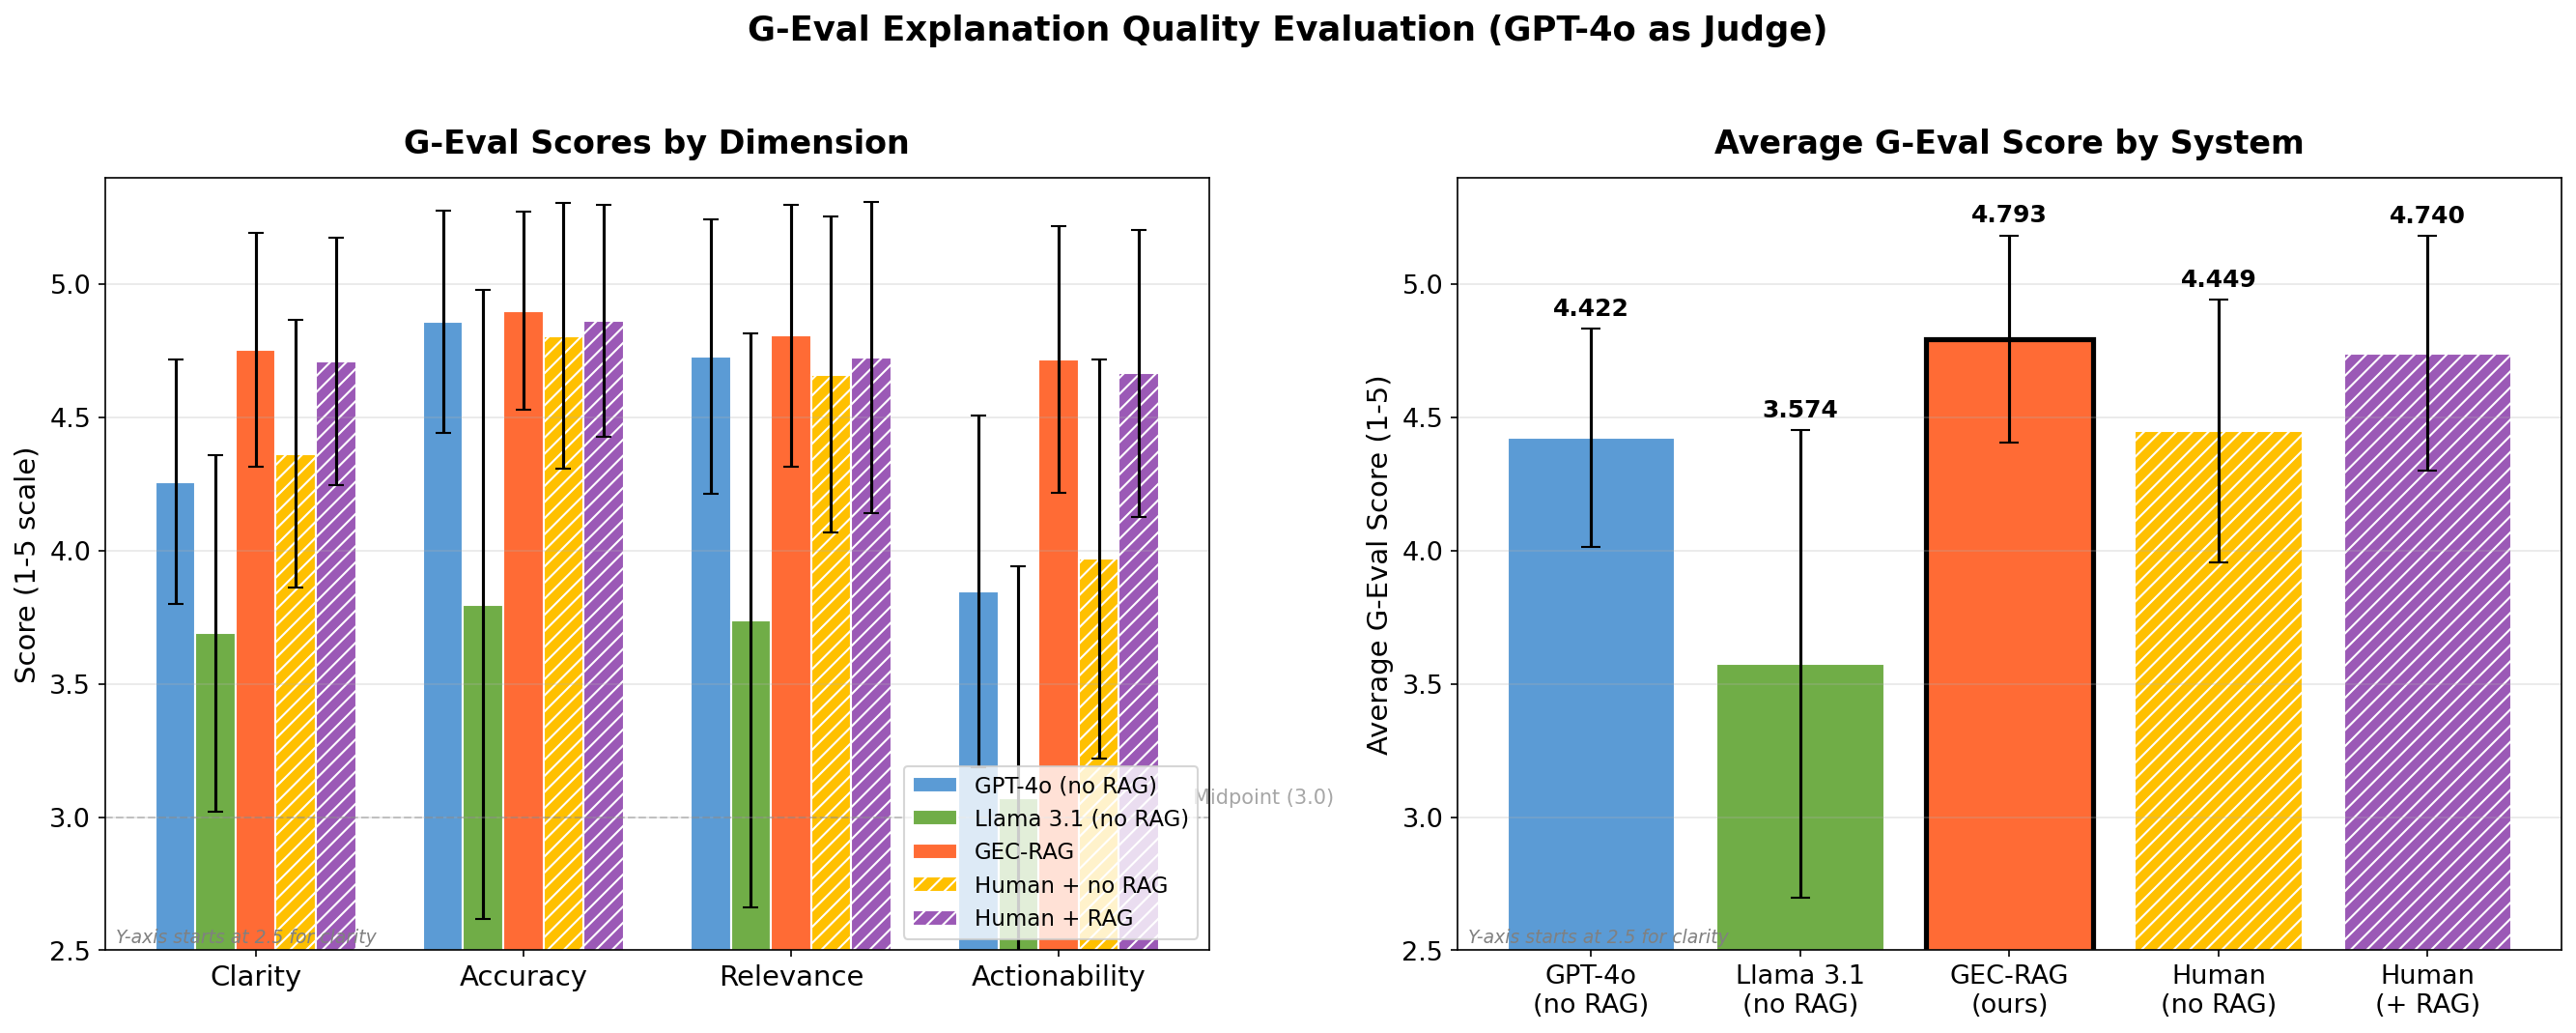

✅ Figure 1 saved (PDF + PNG)


In [4]:
dimensions   = ['clarity', 'accuracy', 'relevance', 'actionability']
dim_labels   = ['Clarity', 'Accuracy', 'Relevance', 'Actionability']
system_order = ['GPT-4o (no RAG)', 'Llama 3.1 (no RAG)', 'GEC-RAG', 'Human + no RAG', 'Human + RAG']
colors       = ['#5B9BD5', '#70AD47', '#FF6B35', '#FFC000', '#9B59B6']
hatches      = ['', '', '', '///', '///']

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# --- Plot 1: Per dimension grouped bar ---
x     = np.arange(len(dimensions))
width = 0.15
n_sys = len(system_order)

for i, (system, color, hatch) in enumerate(zip(system_order, colors, hatches)):
    if system not in geval_summaries:
        continue
    s     = geval_summaries[system]
    means = [s[f'{d}_mean'] for d in dimensions]
    stds  = [s[f'{d}_std']  for d in dimensions]
    offset = (i - n_sys/2 + 0.5) * width

    axes[0].bar(
        x + offset, means, width,
        yerr=stds, label=system,
        color=color, hatch=hatch,
        capsize=4, edgecolor='white',
        error_kw={'linewidth': 1.5}
    )

axes[0].set_xticks(x)
axes[0].set_xticklabels(dim_labels, fontsize=14)
axes[0].set_ylabel('Score (1-5 scale)', fontsize=14)
axes[0].set_ylim(2.5, 5.4)
axes[0].set_title('G-Eval Scores by Dimension', fontsize=16, fontweight='bold', pad=12)
axes[0].legend(fontsize=11, loc='lower right')
axes[0].axhline(y=3, color='gray', linestyle='--', alpha=0.4, linewidth=1)
axes[0].text(3.5, 3.05, 'Midpoint (3.0)', color='gray', fontsize=10, alpha=0.7)
axes[0].set_yticks([2.5, 3.0, 3.5, 4.0, 4.5, 5.0])
axes[0].grid(axis='y', alpha=0.3)
axes[0].annotate('Y-axis starts at 2.5 for clarity', xy=(0.01, 0.01),
                 xycoords='axes fraction', fontsize=9, color='gray', style='italic')

# --- Plot 2: Average score comparison ---
avg_means = []
avg_stds  = []
valid_sys = []

for system in system_order:
    if system in geval_summaries:
        avg_means.append(geval_summaries[system]['average_mean'])
        avg_stds.append(geval_summaries[system]['average_std'])
        valid_sys.append(system)

x2   = np.arange(len(valid_sys))
bars = axes[1].bar(
    x2, avg_means,
    yerr=avg_stds,
    color=[colors[system_order.index(s)] for s in valid_sys],
    hatch=[hatches[system_order.index(s)] for s in valid_sys],
    capsize=5, edgecolor='white',
    error_kw={'linewidth': 1.5}
)

# Short x-axis labels
short_labels = [
    'GPT-4o\n(no RAG)',
    'Llama 3.1\n(no RAG)',
    'GEC-RAG\n(ours)',
    'Human\n(no RAG)',
    'Human\n(+ RAG)'
]
axes[1].set_xticks(x2)
axes[1].set_xticklabels(short_labels[:len(valid_sys)], fontsize=13)
axes[1].set_ylabel('Average G-Eval Score (1-5)', fontsize=14)
axes[1].set_ylim(2.5, 5.4)
axes[1].set_title('Average G-Eval Score by System', fontsize=16, fontweight='bold', pad=12)
axes[1].set_yticks([2.5, 3.0, 3.5, 4.0, 4.5, 5.0])
axes[1].grid(axis='y', alpha=0.3)
axes[1].annotate('Y-axis starts at 2.5 for clarity', xy=(0.01, 0.01),
                 xycoords='axes fraction', fontsize=9, color='gray', style='italic')

for bar, val, std in zip(bars, avg_means, avg_stds):
    axes[1].text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + std + 0.05,
        f'{val:.3f}',
        ha='center', fontweight='bold', fontsize=12
    )

# Highlight GEC-RAG bar
gecrag_idx = valid_sys.index('GEC-RAG') if 'GEC-RAG' in valid_sys else None
if gecrag_idx is not None:
    bars[gecrag_idx].set_edgecolor('black')
    bars[gecrag_idx].set_linewidth(2.5)

plt.suptitle(
    'G-Eval Explanation Quality Evaluation (GPT-4o as Judge)',
    fontsize=17, fontweight='bold', y=1.02
)
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'fig1_geval_scores.pdf'), format='pdf')
plt.savefig(os.path.join(FIGURES_DIR, 'fig1_geval_scores.png'))
plt.show()
print('\u2705 Figure 1 saved (PDF + PNG)')

---
### Cell 5 — Figure 2: Actionability Deep Dive (Key Finding)

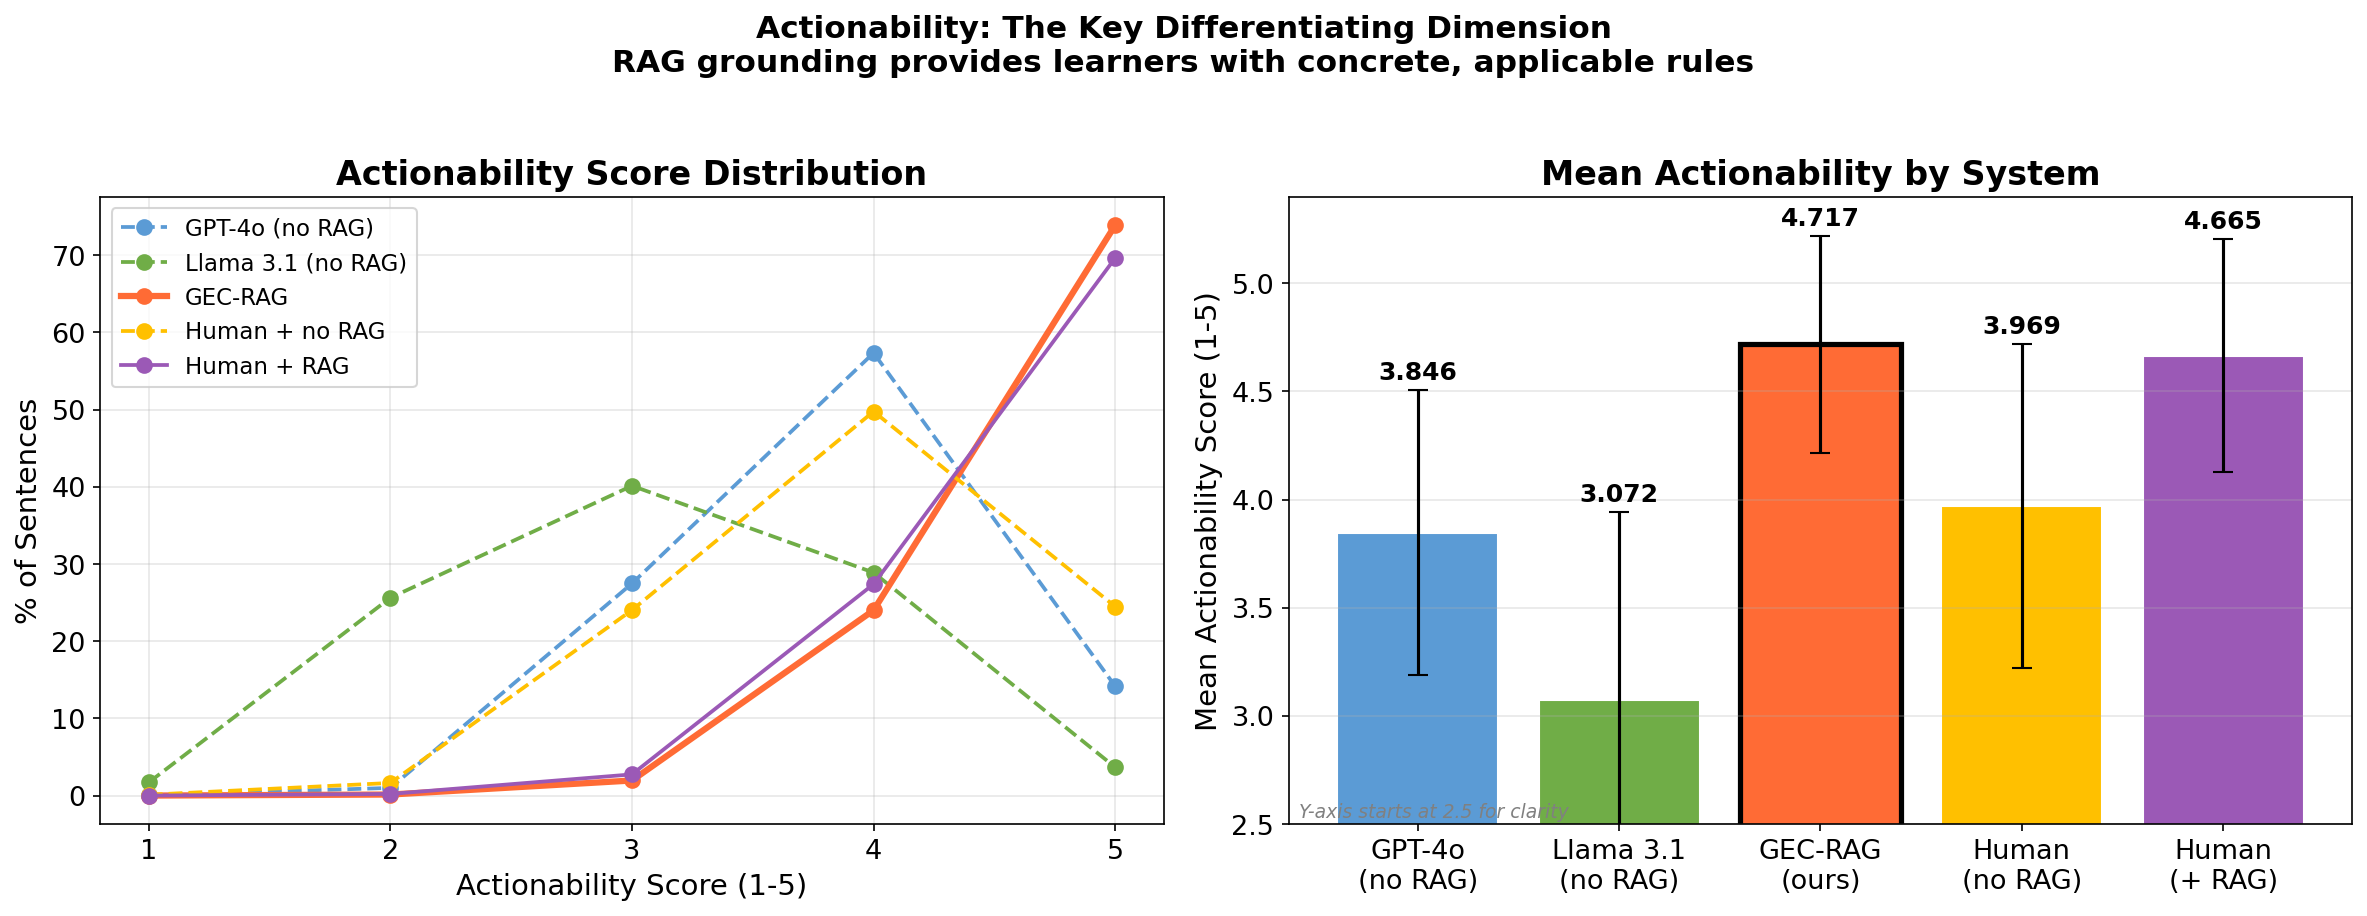

✅ Figure 2 saved


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Left: Score distributions for Actionability
score_vals = range(1, 6)
for system, color in zip(system_order, colors):
    if system not in geval_raw:
        continue
    df     = geval_raw[system]
    total  = len(df)
    pcts   = [len(df[df['actionability'] == v]) / total * 100 for v in score_vals]
    lw     = 3.0 if system == 'GEC-RAG' else 1.8
    ls     = '-'  if system in ['GEC-RAG', 'Human + RAG'] else '--'
    axes[0].plot(score_vals, pcts, marker='o', color=color,
                 linewidth=lw, linestyle=ls, label=system, markersize=7)

axes[0].set_xlabel('Actionability Score (1-5)', fontsize=14)
axes[0].set_ylabel('% of Sentences', fontsize=14)
axes[0].set_title('Actionability Score Distribution', fontsize=16, fontweight='bold')
axes[0].legend(fontsize=11)
axes[0].grid(alpha=0.3)
axes[0].set_xticks(range(1, 6))

# Right: Mean actionability comparison
act_means = []
act_stds  = []
act_sys   = []
for system in system_order:
    if system in geval_summaries:
        act_means.append(geval_summaries[system]['actionability_mean'])
        act_stds.append(geval_summaries[system]['actionability_std'])
        act_sys.append(system)

short_labels = ['GPT-4o\n(no RAG)', 'Llama 3.1\n(no RAG)',
                'GEC-RAG\n(ours)', 'Human\n(no RAG)', 'Human\n(+ RAG)']

bars = axes[1].bar(
    range(len(act_sys)), act_means,
    yerr=act_stds,
    color=[colors[system_order.index(s)] for s in act_sys],
    capsize=5, edgecolor='white',
    error_kw={'linewidth': 1.5}
)
axes[1].set_xticks(range(len(act_sys)))
axes[1].set_xticklabels(short_labels[:len(act_sys)], fontsize=13)
axes[1].set_ylabel('Mean Actionability Score (1-5)', fontsize=14)
axes[1].set_ylim(2.5, 5.4)
axes[1].set_title('Mean Actionability by System', fontsize=16, fontweight='bold')
axes[1].grid(axis='y', alpha=0.3)
axes[1].annotate('Y-axis starts at 2.5 for clarity', xy=(0.01, 0.01),
                 xycoords='axes fraction', fontsize=9, color='gray', style='italic')

for bar, val, std in zip(bars, act_means, act_stds):
    axes[1].text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + std + 0.05,
        f'{val:.3f}', ha='center', fontweight='bold', fontsize=12
    )

# Highlight GEC-RAG
if 'GEC-RAG' in act_sys:
    idx = act_sys.index('GEC-RAG')
    bars[idx].set_edgecolor('black')
    bars[idx].set_linewidth(2.5)

plt.suptitle(
    'Actionability: The Key Differentiating Dimension\n'
    'RAG grounding provides learners with concrete, applicable rules',
    fontsize=15, fontweight='bold', y=1.02
)
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'fig2_actionability.pdf'), format='pdf')
plt.savefig(os.path.join(FIGURES_DIR, 'fig2_actionability.png'))
plt.show()
print('\u2705 Figure 2 saved')

---
### Cell 6 — Figure 3: F0.5 Comparison (Correction Quality)

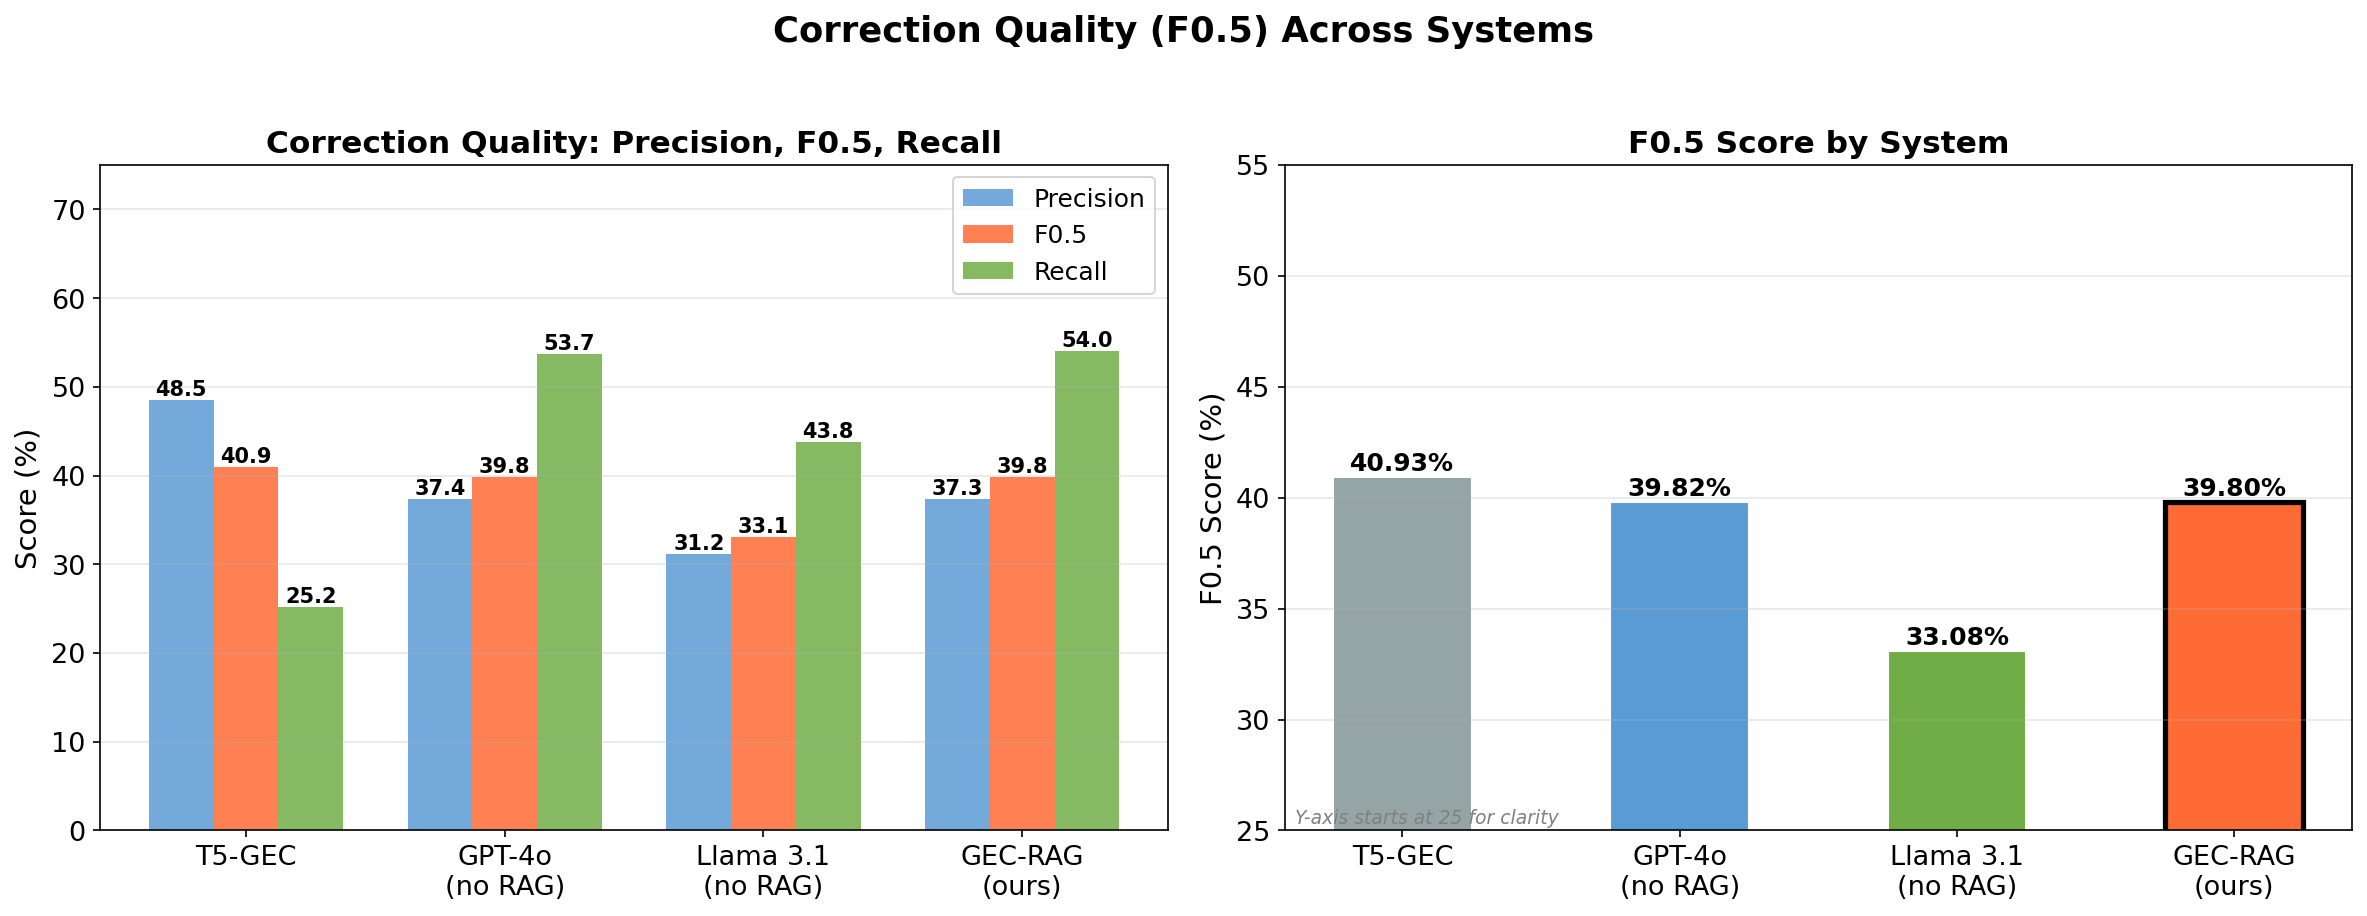

✅ Figure 3 saved


In [6]:
f05_systems = ['T5-GEC', 'GPT-4o-mini (no RAG)', 'Llama-3.1-8B (no RAG)', 'GEC-RAG (GPT-4o-mini + KB)']
f05_labels  = ['T5-GEC', 'GPT-4o\n(no RAG)', 'Llama 3.1\n(no RAG)', 'GEC-RAG\n(ours)']
f05_colors  = ['#95A5A6', '#5B9BD5', '#70AD47', '#FF6B35']

f05_vals  = [f05_scores.get(s, {}).get('f05', 0)      for s in f05_systems]
prec_vals = [f05_scores.get(s, {}).get('precision', 0) for s in f05_systems]
rec_vals  = [f05_scores.get(s, {}).get('recall', 0)    for s in f05_systems]

x     = np.arange(len(f05_systems))
width = 0.25

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Left: F0.5, Precision, Recall grouped
axes[0].bar(x - width, prec_vals, width, label='Precision', color='#5B9BD5', alpha=0.85)
axes[0].bar(x,         f05_vals,  width, label='F0.5',      color='#FF6B35', alpha=0.85)
axes[0].bar(x + width, rec_vals,  width, label='Recall',    color='#70AD47', alpha=0.85)

axes[0].set_xticks(x)
axes[0].set_xticklabels(f05_labels, fontsize=13)
axes[0].set_ylabel('Score (%)', fontsize=14)
axes[0].set_ylim(0, 75)
axes[0].set_title('Correction Quality: Precision, F0.5, Recall', fontsize=15, fontweight='bold')
axes[0].legend(fontsize=12)
axes[0].grid(axis='y', alpha=0.3)

for i, (p, f, r) in enumerate(zip(prec_vals, f05_vals, rec_vals)):
    axes[0].text(i - width, p + 0.5, f'{p:.1f}', ha='center', fontsize=10, fontweight='bold')
    axes[0].text(i,         f + 0.5, f'{f:.1f}', ha='center', fontsize=10, fontweight='bold')
    axes[0].text(i + width, r + 0.5, f'{r:.1f}', ha='center', fontsize=10, fontweight='bold')

# Right: F0.5 only with annotations
bars = axes[1].bar(
    x, f05_vals, color=f05_colors,
    edgecolor='white', width=0.5
)
axes[1].set_xticks(x)
axes[1].set_xticklabels(f05_labels, fontsize=13)
axes[1].set_ylabel('F0.5 Score (%)', fontsize=14)
axes[1].set_ylim(25, 55)
axes[1].set_title('F0.5 Score by System', fontsize=15, fontweight='bold')
axes[1].grid(axis='y', alpha=0.3)
axes[1].annotate('Y-axis starts at 25 for clarity', xy=(0.01, 0.01),
                 xycoords='axes fraction', fontsize=9, color='gray', style='italic')

for bar, val in zip(bars, f05_vals):
    axes[1].text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 0.3,
        f'{val:.2f}%', ha='center', fontweight='bold', fontsize=12
    )

# Highlight GEC-RAG
bars[3].set_edgecolor('black')
bars[3].set_linewidth(2.5)

plt.suptitle('Correction Quality (F0.5) Across Systems',
             fontsize=17, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'fig3_f05_scores.pdf'), format='pdf')
plt.savefig(os.path.join(FIGURES_DIR, 'fig3_f05_scores.png'))
plt.show()
print('\u2705 Figure 3 saved')

---
### Cell 7 — Figure 4: Per Error-Type F0.5 (Top Error Types)

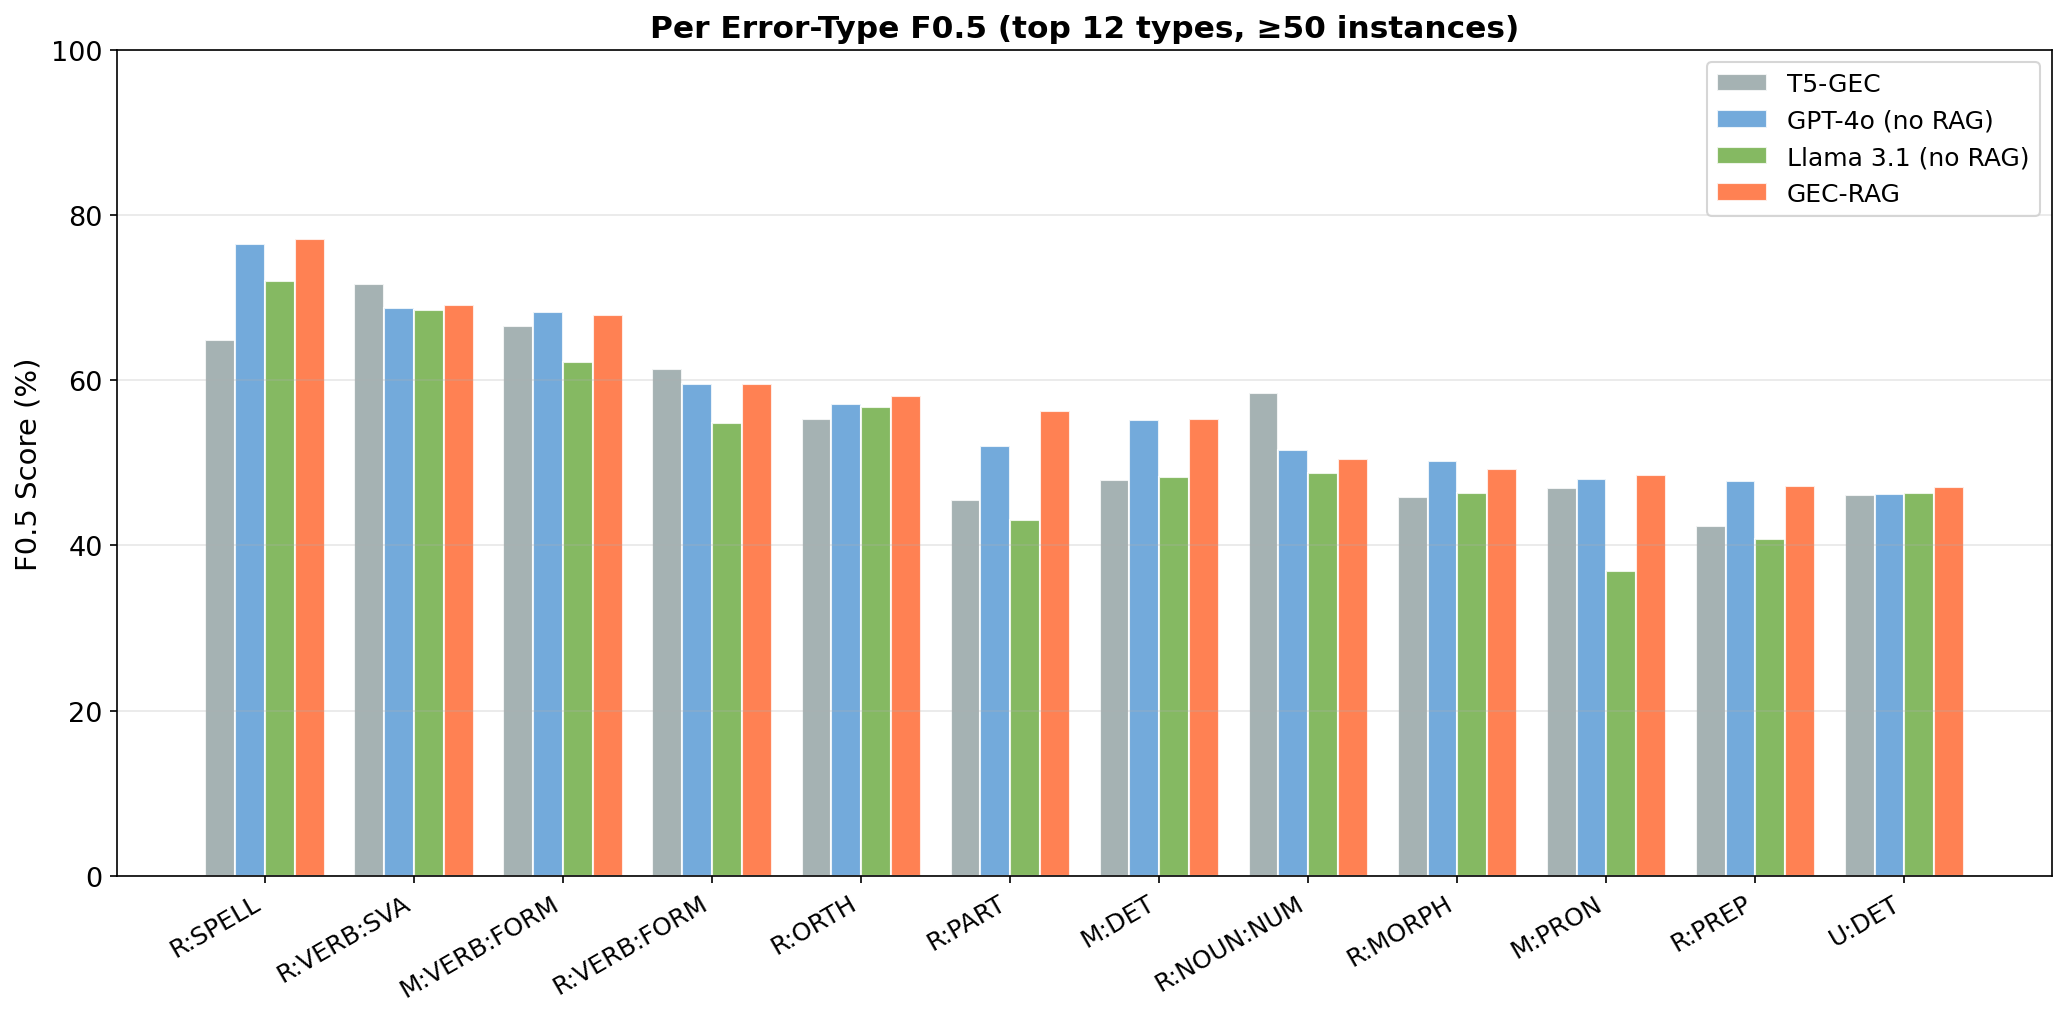

✅ Figure 4 saved
   Error types shown (>=50 instances): ['R:SPELL', 'R:VERB:SVA', 'M:VERB:FORM', 'R:VERB:FORM', 'R:ORTH', 'R:PART', 'M:DET', 'R:NOUN:NUM', 'R:MORPH', 'M:PRON', 'R:PREP', 'U:DET']


In [7]:
# Filter to error types with >= 50 instances (statistically meaningful)
MIN_INSTANCES = 50

pt_systems = ['T5-GEC', 'GPT-4o (no RAG)', 'Llama 3.1 (no RAG)', 'GEC-RAG']
pt_colors  = ['#95A5A6', '#5B9BD5', '#70AD47', '#FF6B35']

# Get common error types across all systems with >= 50 instances
all_types = set()
for label, df in per_type.items():
    sufficient = df[(df['tp']+df['fp']+df['fn']) >= MIN_INSTANCES]
    sufficient = sufficient[~sufficient['error_type'].str.contains('OTHER')]
    all_types.update(sufficient['error_type'].tolist())

# Build comparison dataframe
rows = []
for etype in sorted(all_types):
    row = {'error_type': etype}
    for label in pt_systems:
        if label in per_type:
            match = per_type[label][per_type[label]['error_type'] == etype]
            row[label] = match['f05'].values[0] if len(match) > 0 else 0
        else:
            row[label] = 0
    rows.append(row)

compare_df = pd.DataFrame(rows).set_index('error_type')
compare_df = compare_df.sort_values('GEC-RAG', ascending=False).head(12)

fig, ax = plt.subplots(figsize=(14, 7))
x     = np.arange(len(compare_df))
width = 0.2

for i, (label, color) in enumerate(zip(pt_systems, pt_colors)):
    if label in compare_df.columns:
        offset = (i - len(pt_systems)/2 + 0.5) * width
        ax.bar(x + offset, compare_df[label], width,
               label=label, color=color, alpha=0.85, edgecolor='white')

ax.set_xticks(x)
ax.set_xticklabels(compare_df.index, rotation=30, ha='right', fontsize=12)
ax.set_ylabel('F0.5 Score (%)', fontsize=14)
ax.set_title(
    f'Per Error-Type F0.5 (top 12 types, \u2265{MIN_INSTANCES} instances)',
    fontsize=15, fontweight='bold'
)
ax.legend(fontsize=12)
ax.grid(axis='y', alpha=0.3)
ax.set_ylim(0, 100)

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'fig4_per_type_f05.pdf'), format='pdf')
plt.savefig(os.path.join(FIGURES_DIR, 'fig4_per_type_f05.png'))
plt.show()
print('\u2705 Figure 4 saved')
print(f'   Error types shown (>={MIN_INSTANCES} instances): {list(compare_df.index)}')

---
### Cell 8 — Statistical Significance Testing

In [8]:
print('='*65)
print('STATISTICAL SIGNIFICANCE TESTING')
print('Wilcoxon signed-rank test (paired, non-parametric)')
print('='*65)

dimensions = ['clarity', 'accuracy', 'relevance', 'actionability', 'average']

# Compare GEC-RAG vs each baseline on aligned sentences
# Find common original sentences across systems
def get_common_scores(df1, df2, dim):
    merged = pd.merge(
        df1[['original', dim]].rename(columns={dim: 'score1'}),
        df2[['original', dim]].rename(columns={dim: 'score2'}),
        on='original'
    )
    return merged['score1'].values, merged['score2'].values

if 'GEC-RAG' in geval_raw:
    gecrag_df = geval_raw['GEC-RAG']
    comparisons = [
        ('GPT-4o (no RAG)',    'GPT-4o (no RAG)'),
        ('Llama 3.1 (no RAG)', 'Llama 3.1 (no RAG)'),
        ('Human + no RAG',     'Human + no RAG'),
        ('Human + RAG',        'Human + RAG'),
    ]

    for label, key in comparisons:
        if key not in geval_raw:
            continue
        other_df = geval_raw[key]
        print(f'\nGEC-RAG vs {label}:')
        print(f'  {"Dimension":<15} {"GEC-RAG":>10} {"Baseline":>10} {"p-value":>10} {"Sig":>6}')
        print(f'  {"-"*53}')

        for dim in dimensions:
            try:
                s1, s2 = get_common_scores(gecrag_df, other_df, dim)
                if len(s1) < 20:
                    continue
                stat, p = stats.wilcoxon(s1, s2, alternative='two-sided')
                sig = '***' if p < 0.001 else ('**' if p < 0.01 else ('*' if p < 0.05 else 'n.s.'))
                m1  = np.mean(s1)
                m2  = np.mean(s2)
                print(f'  {dim:<15} {m1:>10.3f} {m2:>10.3f} {p:>10.4f} {sig:>6}')
            except Exception as e:
                print(f'  {dim:<15} Error: {e}')

print(f'\n  * p<0.05  ** p<0.01  *** p<0.001  n.s. = not significant')

STATISTICAL SIGNIFICANCE TESTING
Wilcoxon signed-rank test (paired, non-parametric)

GEC-RAG vs GPT-4o (no RAG):
  Dimension          GEC-RAG   Baseline    p-value    Sig
  -----------------------------------------------------
  clarity              4.753      4.263     0.0000    ***
  accuracy             4.900      4.860     0.0000    ***
  relevance            4.808      4.733     0.0000    ***
  actionability        4.720      3.858     0.0000    ***
  average              4.795      4.429     0.0000    ***

GEC-RAG vs Llama 3.1 (no RAG):
  Dimension          GEC-RAG   Baseline    p-value    Sig
  -----------------------------------------------------
  clarity              4.753      3.688     0.0000    ***
  accuracy             4.902      3.815     0.0000    ***
  relevance            4.813      3.782     0.0000    ***
  actionability        4.721      3.093     0.0000    ***
  average              4.797      3.595     0.0000    ***

GEC-RAG vs Human + no RAG:
  Dimension        

---
### Cell 9 — Figure 5: RAG vs No-RAG Improvement (Key Contribution Figure)

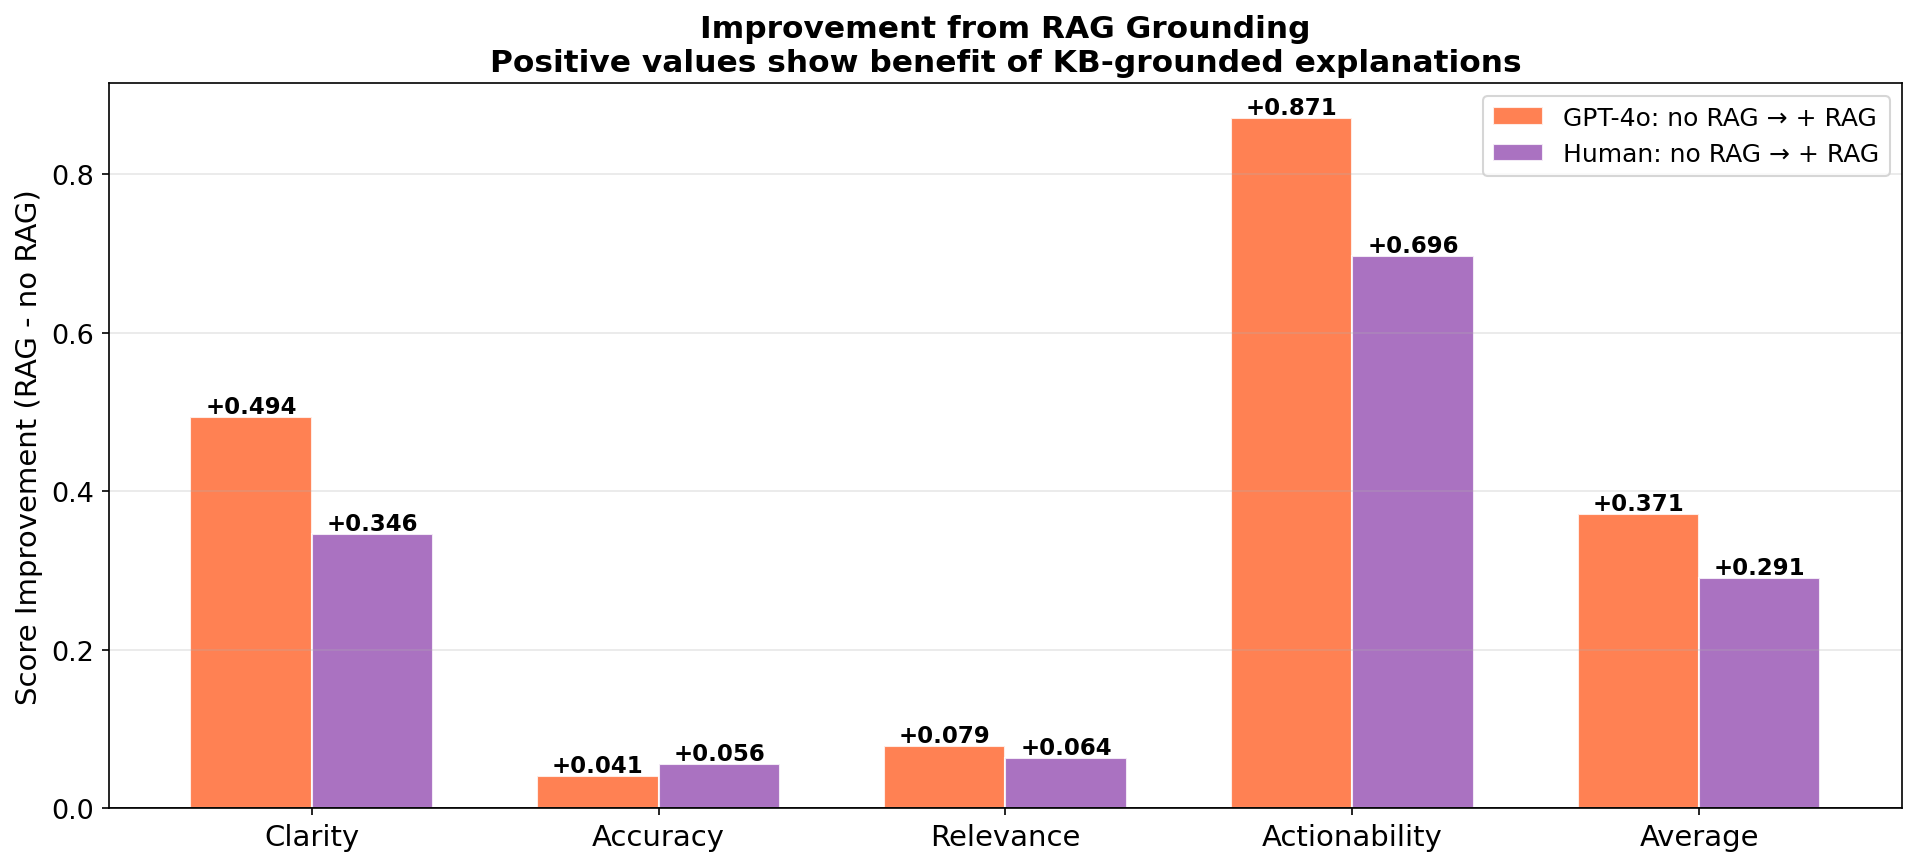

✅ Figure 5 saved


In [9]:
# Show improvement from no-RAG to RAG for both GPT-4o and Human conditions
dimensions  = ['clarity', 'accuracy', 'relevance', 'actionability', 'average']
dim_labels  = ['Clarity', 'Accuracy', 'Relevance', 'Actionability', 'Average']

pairs = [
    ('GPT-4o (no RAG)', 'GEC-RAG',        'GPT-4o: no RAG \u2192 + RAG', '#5B9BD5', '#FF6B35'),
    ('Human + no RAG',  'Human + RAG',     'Human: no RAG \u2192 + RAG',  '#FFC000', '#9B59B6'),
]

fig, ax = plt.subplots(figsize=(13, 6))
x     = np.arange(len(dimensions))
width = 0.35

for i, (base_sys, rag_sys, label, c_base, c_rag) in enumerate(pairs):
    if base_sys not in geval_summaries or rag_sys not in geval_summaries:
        continue
    base_means = [geval_summaries[base_sys][f'{d}_mean'] for d in dimensions]
    rag_means  = [geval_summaries[rag_sys][f'{d}_mean']  for d in dimensions]
    improvements = [r - b for r, b in zip(rag_means, base_means)]

    offset = (i - len(pairs)/2 + 0.5) * width
    bars = ax.bar(
        x + offset, improvements, width,
        label=label,
        color=[c_rag if v >= 0 else '#E74C3C' for v in improvements],
        alpha=0.85, edgecolor='white'
    )
    for bar, val in zip(bars, improvements):
        ax.text(
            bar.get_x() + bar.get_width()/2,
            bar.get_height() + (0.005 if val >= 0 else -0.025),
            f'{val:+.3f}',
            ha='center', fontsize=11, fontweight='bold'
        )

ax.axhline(y=0, color='black', linewidth=1.2)
ax.set_xticks(x)
ax.set_xticklabels(dim_labels, fontsize=14)
ax.set_ylabel('Score Improvement (RAG - no RAG)', fontsize=14)
ax.set_title(
    'Improvement from RAG Grounding\n'
    'Positive values show benefit of KB-grounded explanations',
    fontsize=15, fontweight='bold'
)
ax.legend(fontsize=12)
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'fig5_rag_improvement.pdf'), format='pdf')
plt.savefig(os.path.join(FIGURES_DIR, 'fig5_rag_improvement.png'))
plt.show()
print('\u2705 Figure 5 saved')

---
### Cell 10 — Qualitative Examples Table for Paper

In [10]:
# Find best qualitative examples showing RAG vs no-RAG difference
# Look for sentences where GEC-RAG relevance > GPT-4o relevance by >= 2 points

if 'GEC-RAG' in geval_raw and 'GPT-4o (no RAG)' in geval_raw:
    gecrag_df = geval_raw['GEC-RAG'].copy()
    gpt4o_df  = geval_raw['GPT-4o (no RAG)'].copy()

    merged = pd.merge(
        gecrag_df[['original','corrected','explanation','relevance','actionability','average']].rename(
            columns={'explanation':'gecrag_expl','relevance':'gecrag_rel',
                     'actionability':'gecrag_act','average':'gecrag_avg'}
        ),
        gpt4o_df[['original','explanation','relevance','actionability','average']].rename(
            columns={'explanation':'gpt4o_expl','relevance':'gpt4o_rel',
                     'actionability':'gpt4o_act','average':'gpt4o_avg'}
        ),
        on='original'
    )

    # Find cases where RAG clearly outperforms on relevance
    merged['rel_diff'] = merged['gecrag_rel'] - merged['gpt4o_rel']
    merged['act_diff'] = merged['gecrag_act'] - merged['gpt4o_act']
    best = merged[
        (merged['rel_diff'] >= 2) &
        (merged['act_diff'] >= 1)
    ].sort_values('rel_diff', ascending=False)

    sep = '='*70
    print(sep)
    print('QUALITATIVE EXAMPLES: GEC-RAG vs GPT-4o (no RAG)')
    print('Cases where RAG grounding provides clearly better explanations')
    print(sep)

    for i, (_, row) in enumerate(best.head(3).iterrows()):
        print(f'\nExample {i+1}:')
        print(f'  Original  : {row["original"]}')
        print(f'  Corrected : {row["corrected"]}')
        print(f'\n  GPT-4o (no RAG) [Relevance: {row["gpt4o_rel"]}/5, Action: {row["gpt4o_act"]}/5]:')
        print(f'  {row["gpt4o_expl"][:300]}...')
        print(f'\n  GEC-RAG [Relevance: {row["gecrag_rel"]}/5, Action: {row["gecrag_act"]}/5]:')
        print(f'  {row["gecrag_expl"][:300]}...')
        print(f'  {"-"*68}')

    # Save examples to CSV for paper
    best.head(10).to_csv(os.path.join(RESULTS_DIR, 'qualitative_examples.csv'), index=False)
    print(f'\n\u2705 Top 10 qualitative examples saved: results/qualitative_examples.csv')

QUALITATIVE EXAMPLES: GEC-RAG vs GPT-4o (no RAG)
Cases where RAG grounding provides clearly better explanations

Example 1:
  Original  : When we are from 3 to 5 years old, we learn music from school.
  Corrected : When we are from 3 to 5 years old, we learn music at school.

  GPT-4o (no RAG) [Relevance: 2/5, Action: 3/5]:
  The preposition 'from' should be replaced with 'at' to correctly indicate the location where learning occurs. 'At school' is the standard phrase used to describe learning in an educational institution....

  GEC-RAG [Relevance: 5/5, Action: 5/5]:
  Your original sentence was: "When we are from 3 to 5 years old, we learn music from school." The correction is: "When we are from 3 to 5 years old, we learn music at school."

The error was using "from" instead of "at." In English, we use "at" when talking about places where we learn or do activitie...
  --------------------------------------------------------------------

Example 2:
  Original  : On the other hand, tho

---
### Cell 11 — Summary Statistics for Paper

In [11]:
sep = '='*65
print(sep)
print('SUMMARY STATISTICS FOR PAPER')
print(sep)

# G-Eval improvement of GEC-RAG over GPT-4o no RAG
if 'GEC-RAG' in geval_summaries and 'GPT-4o (no RAG)' in geval_summaries:
    gecrag_avg  = geval_summaries['GEC-RAG']['average_mean']
    gpt4o_avg   = geval_summaries['GPT-4o (no RAG)']['average_mean']
    improvement = gecrag_avg - gpt4o_avg

    print(f'\n\U0001f4ca G-Eval Improvement (GEC-RAG over GPT-4o no RAG):')
    print(f'   Average     : +{improvement:.3f} ({improvement/gpt4o_avg*100:.1f}% relative)')
    print(f'   Actionability: +{geval_summaries["GEC-RAG"]["actionability_mean"] - geval_summaries["GPT-4o (no RAG)"]["actionability_mean"]:.3f}')
    print(f'   Relevance   : +{geval_summaries["GEC-RAG"]["relevance_mean"] - geval_summaries["GPT-4o (no RAG)"]["relevance_mean"]:.3f}')

# Distance from human ceiling
if 'Human + RAG' in geval_summaries:
    human_rag_avg = geval_summaries['Human + RAG']['average_mean']
    gap           = human_rag_avg - gecrag_avg
    print(f'\n\U0001f4ca Distance from Human + RAG ceiling:')
    print(f'   GEC-RAG    : {gecrag_avg:.3f}')
    print(f'   Human+RAG  : {human_rag_avg:.3f}')
    print(f'   Gap        : {gap:+.3f} (GEC-RAG {"exceeds" if gap < 0 else "below"} ceiling)')

# F0.5 comparison
print(f'\n\U0001f4ca F0.5 Scores:')
for sys, key in [
    ('T5-GEC',           'T5-GEC'),
    ('GPT-4o (no RAG)',  'GPT-4o-mini (no RAG)'),
    ('Llama 3.1 (no RAG)', 'Llama-3.1-8B (no RAG)'),
    ('GEC-RAG',          'GEC-RAG (GPT-4o-mini + KB)'),
]:
    if key in f05_scores:
        print(f'   {sys:<25} : {f05_scores[key]["f05"]}%')

print(f'\n\U0001f4c1 All figures saved to: {FIGURES_DIR}')
print(f'   fig1_geval_scores.pdf/png')
print(f'   fig2_actionability.pdf/png')
print(f'   fig3_f05_scores.pdf/png')
print(f'   fig4_per_type_f05.pdf/png')
print(f'   fig5_rag_improvement.pdf/png')

SUMMARY STATISTICS FOR PAPER

📊 G-Eval Improvement (GEC-RAG over GPT-4o no RAG):
   Average     : +0.371 (8.4% relative)
   Actionability: +0.871
   Relevance   : +0.079

📊 Distance from Human + RAG ceiling:
   GEC-RAG    : 4.793
   Human+RAG  : 4.740
   Gap        : -0.053 (GEC-RAG exceeds ceiling)

📊 F0.5 Scores:
   T5-GEC                    : 40.93%
   GPT-4o (no RAG)           : 39.82%
   Llama 3.1 (no RAG)        : 33.08%
   GEC-RAG                   : 39.8%

📁 All figures saved to: C:/gecrag\figures
   fig1_geval_scores.pdf/png
   fig2_actionability.pdf/png
   fig3_f05_scores.pdf/png
   fig4_per_type_f05.pdf/png
   fig5_rag_improvement.pdf/png
